# Missing values

Real tables have blanks, and most scikit-learn models refuse to run on them. This notebook shows the two usual fixes: **drop** the rows, or **fill** the blanks with the mean or the median.

This notebook goes with the **Missing values** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

## 1. Load the data

`customers.csv` is a small made-up table of 80 shoppers: their **country**, **age** and **salary**, and whether they **purchased** (1) or not (0). It was generated for this course, so it is free to use. A few ages and salaries are left blank on purpose.

In [1]:
import numpy as np
import pandas as pd

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/customers.csv"
dataset = pd.read_csv(DATA_URL)
dataset.head()

,country,age,salary,purchased
0,Spain,37.0,49000.0,0
1,France,49.0,52000.0,1
2,France,37.0,35000.0,0
3,Germany,33.0,56500.0,1
4,Germany,24.0,29500.0,0


## 2. Find the blanks

Pandas calls a blank `NaN`. `isna()` marks every blank and `sum()` counts them per column.

In [2]:
print(dataset.isna().sum())
print('Rows with at least one blank:', dataset.isna().any(axis=1).sum(), 'of', len(dataset))

country      0
age          6
salary       6
purchased    0
dtype: int64
Rows with at least one blank: 12 of 80


## 3. Option A: drop the rows

Simple, but every row with a blank disappears, including the values that were there.

In [3]:
dropped = dataset.dropna()
print(len(dataset), 'rows before,', len(dropped), 'rows after')
print('Mean age after dropping:   ', round(dropped['age'].mean(), 2))
print('Mean salary after dropping:', round(dropped['salary'].mean()))

80 rows before, 68 rows after
Mean age after dropping:    40.93
Mean salary after dropping: 48213


## 4. Option B: fill with the mean or the median

`SimpleImputer` works out one value per column from the numbers that exist, then writes it into the blanks. Try `strategy='median'` too and compare.

In [4]:
from sklearn.impute import SimpleImputer

numbers = dataset[['age', 'salary']].values
imputer = SimpleImputer(strategy='mean')   # or 'median'
filled = imputer.fit_transform(numbers)

print('Values used to fill [age, salary]:', imputer.statistics_.round(1))
print('Blanks left:', np.isnan(filled).sum(), '| rows kept:', len(filled))

Values used to fill [age, salary]: [4.06000e+01 4.75405e+04]
Blanks left: 0 | rows kept: 80


## 5. Do it the careful way: split first

The fill values should come from the **training** rows only. Otherwise information from the test rows leaks into training. Fit the imputer on the training set, then use it on both sets. (The next lessons explain the split.)

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(numbers, test_size=0.25, random_state=0)

imputer = SimpleImputer(strategy='median')
imputer.fit(X_train)                  # learn from the training rows only
X_train = imputer.transform(X_train)
X_test = imputer.transform(X_test)    # fill the test rows with the training numbers
print('Median age and salary of the training rows:', imputer.statistics_)

Median age and salary of the training rows: [4.00e+01 4.35e+04]


## Try it yourself

- Switch `strategy` to `'median'` in step 4. Which fill value changes more, age or salary?
- Add `strategy='most_frequent'`. When would that make sense?

## See it: what each fix does to the table

Three ways to deal with blanks: **drop** the rows, **fill with the mean**, or **fill with the median**. **Notice how** dropping removes rows, while filling keeps all 80 rows but pulls the average towards the filled value. In the scatter plots, the dots with a thick black ring are the ones that had a blank, so you can see where the filled value landed.

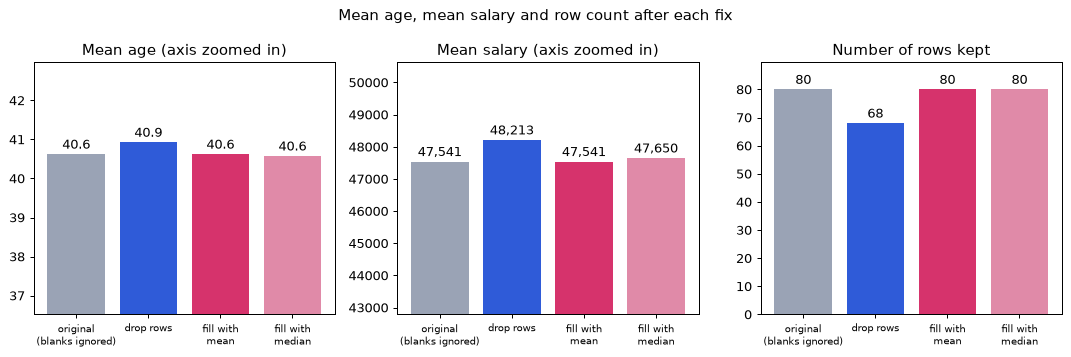

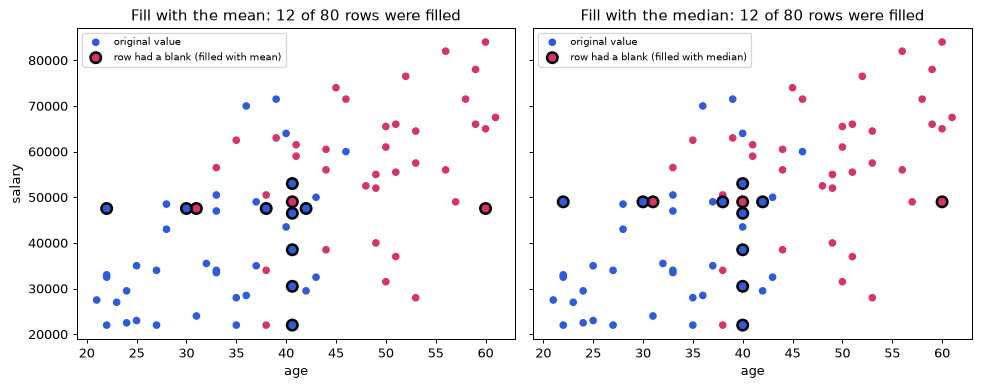

In [6]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer

cols = ['age', 'salary']
variants = {
    'original\n(blanks ignored)': (dataset[cols].mean(), len(dataset)),
}
dropped = dataset.dropna(subset=cols)
variants['drop rows'] = (dropped[cols].mean(), len(dropped))
filled_data = {}
for strat in ['mean', 'median']:
    arr = SimpleImputer(strategy=strat).fit_transform(dataset[cols])
    df = pd.DataFrame(arr, columns=cols)
    filled_data[strat] = df
    variants[f'fill with\n{strat}'] = (df.mean(), len(df))

names = list(variants)
bar_colors = ['#9aa3b5', BLUE, PINK, '#e08aa8']
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col, unit in [(axes[0], 'age', 'years'), (axes[1], 'salary', '')]:
    vals = [variants[n][0][col] for n in names]
    bars = ax.bar(names, vals, color=bar_colors)
    ax.bar_label(bars, labels=[f'{v:,.1f}' if col == 'age' else f'{v:,.0f}' for v in vals], padding=2)
    ax.set_title(f'Mean {col} (axis zoomed in)')
    ax.set_ylim(min(vals) * 0.9, max(vals) * 1.05)
    ax.tick_params(axis='x', labelsize=8)
rows = [variants[n][1] for n in names]
bars = axes[2].bar(names, rows, color=bar_colors)
axes[2].bar_label(bars, padding=2)
axes[2].set_title('Number of rows kept')
axes[2].set_ylim(0, max(rows) * 1.12)
axes[2].tick_params(axis='x', labelsize=8)
fig.suptitle('Mean age, mean salary and row count after each fix')
fig.tight_layout()
plt.show()

had_blank = dataset[cols].isna().any(axis=1).values
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
for ax, strat in zip(axes, ['mean', 'median']):
    df = filled_data[strat]
    colors = np.where(dataset['purchased'] == 1, PINK, BLUE)
    ax.scatter(df.loc[~had_blank, 'age'], df.loc[~had_blank, 'salary'], c=colors[~had_blank], s=26, label='original value')
    ax.scatter(df.loc[had_blank, 'age'], df.loc[had_blank, 'salary'], c=colors[had_blank], s=70,
               edgecolors='black', linewidths=2, label=f'row had a blank (filled with {strat})')
    ax.set_title(f'Fill with the {strat}: {had_blank.sum()} of {len(df)} rows were filled')
    ax.set_xlabel('age')
    ax.legend(loc='upper left', fontsize=8)
axes[0].set_ylabel('salary')
fig.tight_layout()
plt.show()
